# CodeGraph-RAG / PathPack v0.4 — воспроизводимое исследование

Этот блокнот показывает полный цикл одной настоящей dev-задачи и читает результаты пяти методов и шести режимов v0.4 на тех же 20 dev-задачах. Визуализации строятся по сохранённым графам, путям, кандидатам и измеренным метрикам. Все числа загружаются из результатов запуска; вымышленных таблиц здесь нет.

**Запуск:** `source .venv/bin/activate`, затем `jupyter notebook notebooks/04_pathpack_v04.ipynb`. Полный dev-эксперимент: `bash scripts/run_v04_dev.sh` (новая директория через `RUN_OUT`, существующие прогоны не перезаписываются).

**Протокол:** существующие 20 dev / 60 исследовательских test сохранены. Финальный holdout подготовлен отдельно без оценки. Коэффициенты — стартовая эвристика из ТЗ, без подстройки по текущим метрикам. Token budget приблизительный: `ceil(UTF-8 bytes/4)` по полному сериализованному контексту. Это не токенизатор Gemma. Function Recall требует покрытия ≥20% собственных непустых строк тела функции, без docstring и вложенных функций; одних имени/сигнатуры недостаточно. Отдельно измеряются полное покрытие функции и recall изменённых старых строк.


In [1]:
from pathlib import Path
import sys, json, gzip, time
import pandas as pd
from IPython.display import display, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/codegraph_rag').is_dir())
sys.path.insert(0, str(ROOT/'src'))
from codegraph_rag.config import V4Config
from codegraph_rag.parser import scan_repository
from codegraph_rag.adaptive_chunker import build_chunk_index
from codegraph_rag.hybrid_ranker import HybridIndex
from codegraph_rag.pathpack_v4 import PreparedQuery
from codegraph_rag.context_packer import token_count
from codegraph_rag.research_visuals import visualize_run
from codegraph_rag.experiments import verify_snapshot
RUN = ROOT/'output/v04_dev'
metadata = json.loads((RUN/'run.json').read_text())
assert metadata['status'] == 'scored', 'Сначала завершите dev-прогон и score-run'
config = V4Config(**metadata['config'])
print('Run:', RUN, '| tasks:', len(metadata['issues']), '| code:', metadata['code_sha256'])
print('Counter:', metadata['token_counter'])
display(pd.Series(config.to_dict(),name='configuration'))


Run: /Users/aleksandrvorobev/Downloads/CodeGraph-RAG-v0.2/output/v04_dev | tasks: 20 | code: 60b57847ddaaed065d97022f2d61b3d3f4fb17c35e1755d82a8509aa11465ae6
Counter: utf8_bytes_div4_ceil_serialized_context_v1


target_chunk_tokens                                                      128
max_chunk_tokens                                                         256
min_chunk_tokens                                                          32
chunk_overlap_lines                                                        2
lexical_weight                                                          0.45
symbol_weight                                                            0.2
graph_weight                                                            0.25
diversity_weight                                                         0.1
redundancy_strength                                                      0.5
file_diversity_exponent                                                  1.0
cost_offset                                                             32.0
cost_exponent                                                            0.5
hops                                                                       2

## 1. Реальная задача, AST и Function Graph

Запрос берётся из issue manifest, без эталонного patch. Снимок проверяется по `base_commit` и отсутствию изменений tracked-файлов. Граф извлекается из AST без запуска кода библиотеки. Chunk Index хранится отдельно от Function Graph.


In [2]:
issue = metadata['issues'][0]
repo = verify_snapshot(issue, metadata['snapshots'])
print(issue['instance_id'], '| repository:', issue['repo'], '| commit:', issue['base_commit'])
print(issue['problem_statement'][:2500])
t0=time.perf_counter(); graph=scan_repository(repo); scan_sec=time.perf_counter()-t0
print('AST scan seconds:', round(scan_sec,3), '| graph nodes:',len(graph.nodes),'| edges:',len(graph.edges))
print('Parse errors:',len(graph.errors))


django__django-12276 | repository: django/django | commit: 53d8646f799de7f92ab9defe9dc56c6125448102
FileInput shouldn't display required attribute when initial data exists.
Description
	 
		(last modified by thenewguy)
	 
I think that ClearableFileInput.use_required_attribute() (​https://github.com/django/django/blob/e703b93a656b78b9b444bb3a9980e305ed002a70/django/forms/widgets.py#L454) should be moved to FileInput.use_required_attribute() so that required is not output on the html input element that represents FileInput when a file is already set (e.g. already saved on a model instance that is being edited).
Maybe I am overlooking a use case where this is not desirable? I can not think of one.



AST scan seconds: 6.089 | graph nodes: 35490 | edges: 63841
Parse errors: 0


## 2. Adaptive AST Chunking

Короткие функции остаются целыми. Для длинных используются границы AST-инструкций и fallback по строкам/колонкам; индекс может иметь overlap, но упаковщик удаляет повторно передаваемые исходные интервалы. У каждого чанка есть function_id, исходные диапазоны, сигнатура и родитель. Контекст сигнатуры учитывается в стоимости и не используется как доказательство найденного тела функции.


In [3]:
t0=time.perf_counter(); chunk_index=build_chunk_index(repo,graph,config); index=HybridIndex(chunk_index,graph)
print('Chunk/index seconds:',round(time.perf_counter()-t0,3),'| functions:',len(chunk_index.functions),'| chunks:',len(chunk_index.chunks))
chunk_table=pd.DataFrame([c.metadata() for c in chunk_index.chunks])
display(chunk_table[['id','function_id','line_start','line_end','tokens_est']].head(12))
print('Maximum estimated chunk tokens:',int(chunk_table.tokens_est.max()))


Chunk/index seconds: 1.923 | functions: 7890 | chunks: 12971


,id,function_id,line_start,line_end,tokens_est
0,django/__init__.py::setup::chunk_0,django/__init__.py::setup,8,24,197
1,django/__main__.py::__module__::chunk_0,django/__main__.py::__module__,1,9,69
2,django/apps/__init__.py::__module__::chunk_0,django/apps/__init__.py::__module__,1,4,40
3,django/apps/config.py::AppConfig.__init__::chu...,django/apps/config.py::AppConfig.__init__,13,31,109
4,django/apps/config.py::AppConfig.__init__::chu...,django/apps/config.py::AppConfig.__init__,30,49,120
5,django/apps/config.py::AppConfig.__repr__::chu...,django/apps/config.py::AppConfig.__repr__,51,52,51
6,django/apps/config.py::AppConfig._path_from_mo...,django/apps/config.py::AppConfig._path_from_mo...,54,60,77
7,django/apps/config.py::AppConfig._path_from_mo...,django/apps/config.py::AppConfig._path_from_mo...,55,68,162
8,django/apps/config.py::AppConfig._path_from_mo...,django/apps/config.py::AppConfig._path_from_mo...,67,78,200
9,django/apps/config.py::AppConfig._path_from_mo...,django/apps/config.py::AppConfig._path_from_mo...,77,79,75


Maximum estimated chunk tokens: 256


## 3. Hybrid Ranking: объяснение выбора

Лексическая оценка BM25 нормализуется делением на максимум (нулевой вектор остаётся нулевым). Symbol score — доля query terms в имени/пути. Graph score — произведение надёжности типов рёбер и decay по пути от BM25-seeds, не более двух hops по умолчанию. Diversity уменьшает похожесть уже выбранных фрагментов и мягко снижает повторный выбор одного файла. Порядок строится один раз и не зависит от бюджета. Top-512 evidence-кандидатов — явно фиксированный предел конфигурации; остальные получают причину `candidate_limit`.


In [4]:
t0=time.perf_counter(); prepared=PreparedQuery(index,issue['problem_statement'],config); query_sec=time.perf_counter()-t0
print('Query/order seconds:',round(query_sec,3))
print('BM25 seeds:',prepared.seeds)
results={b:prepared.pack(b,instance_id=issue['instance_id']) for b in (1024,2048,4096)}
stored=[json.loads(line) for line in (RUN/f"{issue['instance_id']}_predictions.jsonl").read_text().splitlines()]
stored={p['budget_est']:p for p in stored if p['method']=='pathpack-v4'}
for b,r in results.items(): assert r.context == stored[b]['context'], 'Recomputed context differs from frozen run'
result=results[2048]
candidates=pd.DataFrame(result.diagnostics['candidates'])
columns=['id','bm25_score','lexical_score','symbol_score','graph_score','diversity_contribution','score','utility','tokens_est','selected','decision','graph_path']
display(candidates.sort_values('order').head(15)[columns])
print('Decision counts:',candidates.decision.value_counts().to_dict())


Query/order seconds: 0.463
BM25 seeds: ['django/forms/widgets.py::ClearableFileInput.use_required_attribute', 'django/forms/fields.py::FileField.clean', 'django/forms/widgets.py::CheckboxSelectMultiple.use_required_attribute']


,id,bm25_score,lexical_score,symbol_score,graph_score,diversity_contribution,score,utility,tokens_est,selected,decision,graph_path
10557,django/forms/widgets.py::ClearableFileInput.us...,60.186343,1.000000,0.156250,0.000000,0.100000,0.581250,0.057552,70,True,selected,[django/forms/widgets.py::ClearableFileInput.u...
10394,django/forms/models.py::BaseModelFormSet.valid...,21.797716,0.362170,0.078125,0.640000,0.100000,0.438602,0.038321,99,True,selected,"[django/forms/fields.py::FileField.clean, djan..."
10282,django/forms/formsets.py::BaseFormSet.full_cle...,8.674789,0.144132,0.062500,0.640000,0.093333,0.322781,0.035218,52,True,selected,"[django/forms/fields.py::FileField.clean, djan..."
8268,django/db/models/fields/__init__.py::TimeField...,26.463846,0.439699,0.046875,0.640000,0.092453,0.445834,0.035028,130,True,selected,"[django/forms/fields.py::FileField.clean, djan..."
10591,django/forms/widgets.py::CheckboxSelectMultipl...,51.253317,0.851577,0.109375,0.000000,0.037931,0.394126,0.034836,96,True,selected,[django/forms/widgets.py::CheckboxSelectMultip...
10496,django/forms/utils.py::ErrorList.as_data::chunk_0,10.593067,0.176004,0.062500,0.640000,0.080000,0.306532,0.034488,47,True,selected,"[django/forms/fields.py::FileField.clean, djan..."
10215,django/forms/forms.py::BaseForm._html_output::...,36.779657,0.611096,0.078125,0.000000,0.094118,0.376188,0.033514,94,True,selected,[]
10121,django/forms/fields.py::FileField.clean::chunk_1,56.057980,0.931407,0.062500,0.000000,0.084932,0.484044,0.033089,182,True,selected,[django/forms/fields.py::FileField.clean]
10553,django/forms/widgets.py::ClearableFileInput.is...,42.669583,0.708958,0.140625,0.030976,0.025000,0.335538,0.031848,79,True,selected,[django/forms/widgets.py::ClearableFileInput.u...
4296,django/core/exceptions.py::ValidationError.__i...,28.442939,0.472581,0.031250,0.640000,0.086076,0.438608,0.030559,174,True,selected,"[django/forms/fields.py::FileField.clean, djan..."


Decision counts: {'candidate_limit': 12459, 'after_budget_cutoff': 483, 'selected': 19, 'duplicate_content': 9, 'budget_exceeded': 1}


## 4. Budget-Aware Packing и инварианты

Единый поток содержит только исходный код, заголовки файлов/функций, исходные диапазоны и минимальные сигнатуры. Диагностические оценки в него не входят. Каждый бюджет получает самый длинный допустимый префикс по границам исходных атомов. Заголовок кандидата указывает его исходный диапазон, а точные переданные строки/колонки хранятся в `source_spans`; последний фрагмент может быть частичным.


In [5]:
previous=''
rows=[]
for budget,r in results.items():
    assert r.context.startswith(previous)
    assert token_count(r.context)<=budget
    assert sum(h.chunk.tokens_est for h in r.hits)==token_count(r.context)
    previous=r.context
    rows.append({k:r.diagnostics[k] for k in ('budget_est','tokens_est','remaining_tokens','token_utilization','selected_files','selected_functions','selected_chunks')})
display(pd.DataFrame(rows))
print('Actual context prefix @2048:\n',result.context[:2200])


,budget_est,tokens_est,remaining_tokens,token_utilization,selected_files,selected_functions,selected_chunks
0,1024,1019,5,0.995117,8,10,10
1,2048,2005,43,0.979004,12,18,19
2,4096,4074,22,0.994629,25,33,38


Actual context prefix @2048:
 # File: django/forms/widgets.py
# Function: ClearableFileInput.use_required_attribute
# Lines: 454-455
# Signature: def use_required_attribute(self, initial):
    def use_required_attribute(self, initial):
        return super().use_required_attribute(initial) and not initial


# File: django/forms/models.py
# Function: BaseModelFormSet.validate_unique
# Lines: 735-738
# Signature: def validate_unique(self):
                    else:
                        date_data = (getattr(form.cleaned_data[unique_for], lookup),)
                    data = (form.cleaned_data[field],) + date_data
                    # if we've already seen it then we have a uniqueness failure


# File: django/forms/formsets.py
# Function: BaseFormSet.full_clean
# Lines: 338-340
# Signature: def full_clean(self):
                continue
            self._errors.append(form_errors)
        try:


# File: django/db/models/fields/__init__.py
# Function: TimeField.to_python
# Lines: 2141-2

## 5. Seeds, graph paths, выбранные и отклонённые функции

Синий — BM25-seeds; зелёный — выбранные дополнительные функции; серый — отклонённые кандидаты; жёлтый — промежуточные узлы графа; оранжевые рёбра — графовые пути, реально использованные алгоритмом. Это ограниченный читаемый фрагмент графа первой dev-задачи, а не все узлы репозитория.


{'figures': '/Users/aleksandrvorobev/Downloads/CodeGraph-RAG-v0.2/output/v04_dev/figures', 'instance_id': 'django__django-12276', 'seed_nodes': 3, 'selected_functions': 18, 'chunks': 19}


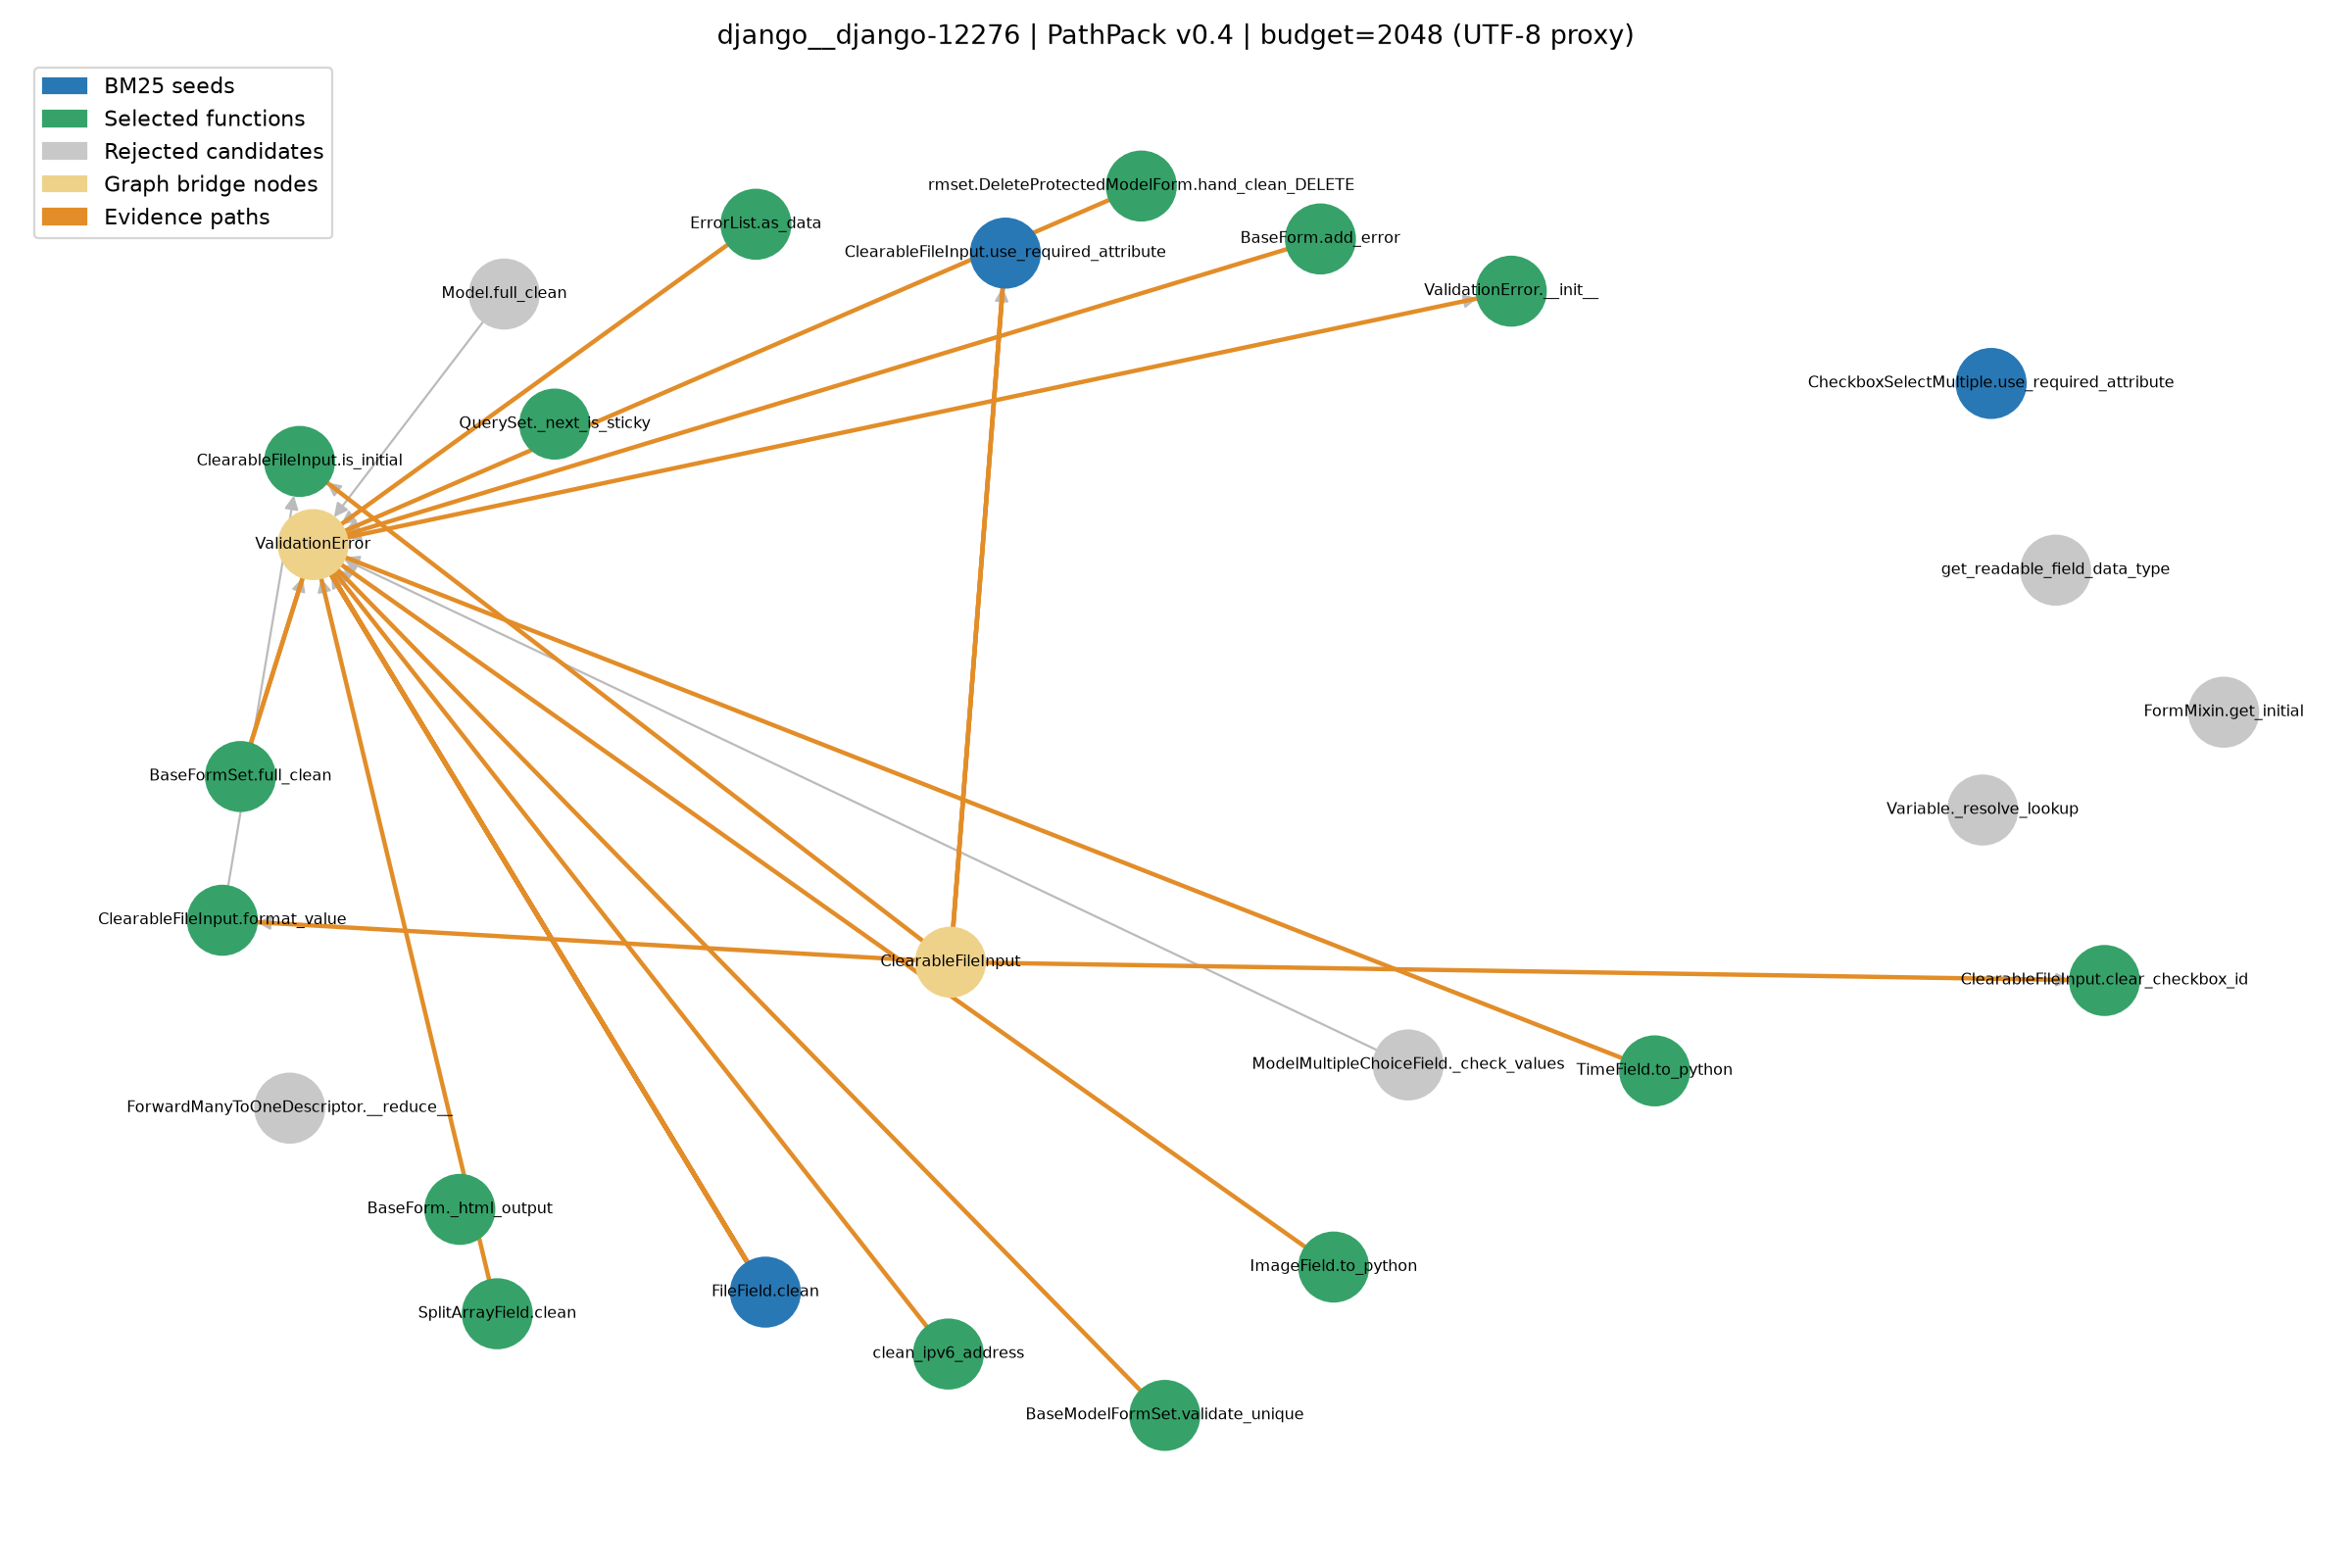

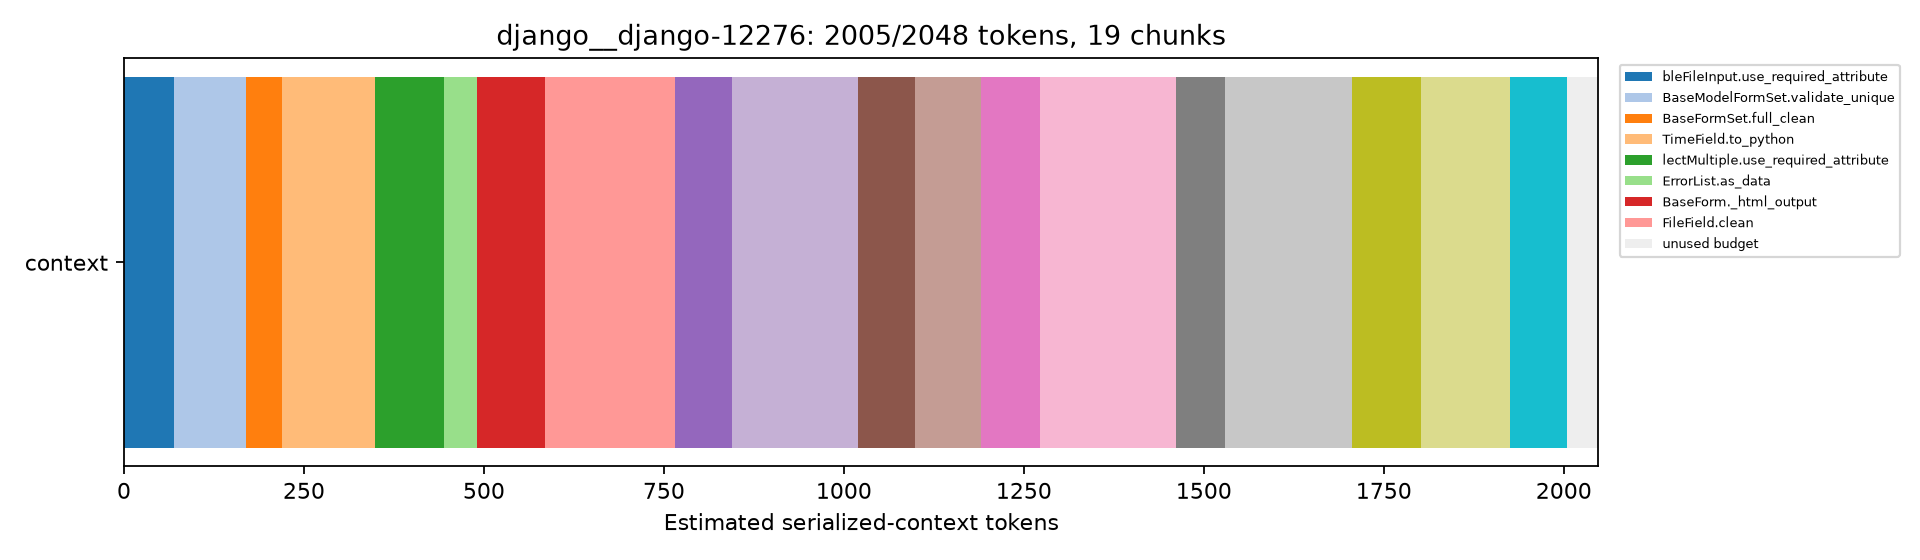

In [6]:
figures=visualize_run(RUN,instance_id=issue['instance_id'],budget=2048)
print(figures)
for name in ('function_graph.png','budget_allocation.png'):
    display(Image(filename=str(RUN/'figures'/name)))


## 6. Пять методов на одинаковых 20 задачах

Старые алгоритмы сохранены. В этом эксперименте для них заново сериализованы заголовки, исходные строки и разделители тем же счётчиком, поэтому результаты не смешиваются с историческими таблицами другого учёта контекста. Indexing и AST-сканирование измеряются отдельно; latency — query scoring + ранжирование + packing, без записи диагностики. Dense baseline пропущен по причине, сохранённой в metadata; облачных вызовов нет.


,method,budget,tasks,file_recall,file_recall_evaluable,function_recall,function_recall_evaluable,complete_function_recall,complete_function_recall_evaluable,changed_line_recall,changed_line_recall_evaluable,latency_sec,token_utilization,tokens_est,useful_functions_per_1k,complete_label_tasks,partial_label_tasks
0,bm25,1024,20,0.225,20,0.1151,18,0.1151,18,0.1480,14,0.0523,0.9876,1011.30,0.1659,4,16
1,bm25,2048,20,0.350,20,0.1111,18,0.1111,18,0.1429,14,0.0517,0.9951,2037.95,0.0545,4,16
2,bm25,4096,20,0.550,20,0.1706,18,0.1706,18,0.2194,14,0.0519,0.9978,4086.85,0.0544,4,16
3,graph-expand,1024,20,0.250,20,0.1111,18,0.1111,18,0.1429,14,0.1674,0.9917,1015.50,0.1088,4,16
4,graph-expand,2048,20,0.325,20,0.1111,18,0.1111,18,0.1429,14,0.1360,0.9938,2035.30,0.0544,4,16
5,graph-expand,4096,20,0.425,20,0.2500,18,0.2500,18,0.2778,14,0.1509,0.9971,4084.05,0.0680,4,16
6,pathpack,1024,20,0.300,20,0.1389,18,0.1389,18,0.1429,14,0.1410,0.9885,1012.25,0.1641,4,16
7,pathpack,2048,20,0.475,20,0.1389,18,0.1389,18,0.1429,14,0.1630,0.9911,2029.70,0.0823,4,16
8,pathpack,4096,20,0.625,20,0.1944,18,0.1944,18,0.1429,14,0.1451,0.9953,4076.95,0.0546,4,16
9,pathpack-v3,1024,20,0.300,20,0.0833,18,0.0833,18,0.0714,14,0.2121,0.8063,825.65,0.1837,4,16


Embedding baseline: {'status': 'unavailable', 'reason': 'No fixed local sentence/code embedding model with compatible installed encoder; no cloud calls or model downloads.'}


,scan_sec,legacy_index_sec,adaptive_index_sec,chunks
count,20.000,20.000,20.000,20.000
mean,5.892,1.494,3.147,15731.050
std,8.341,2.200,4.176,17556.553
min,0.087,0.032,0.070,482.000
25%,1.102,0.366,0.737,4697.250
50%,2.874,0.850,2.060,13163.500
75%,6.078,1.077,2.373,14366.750
max,27.372,7.815,13.227,60226.000


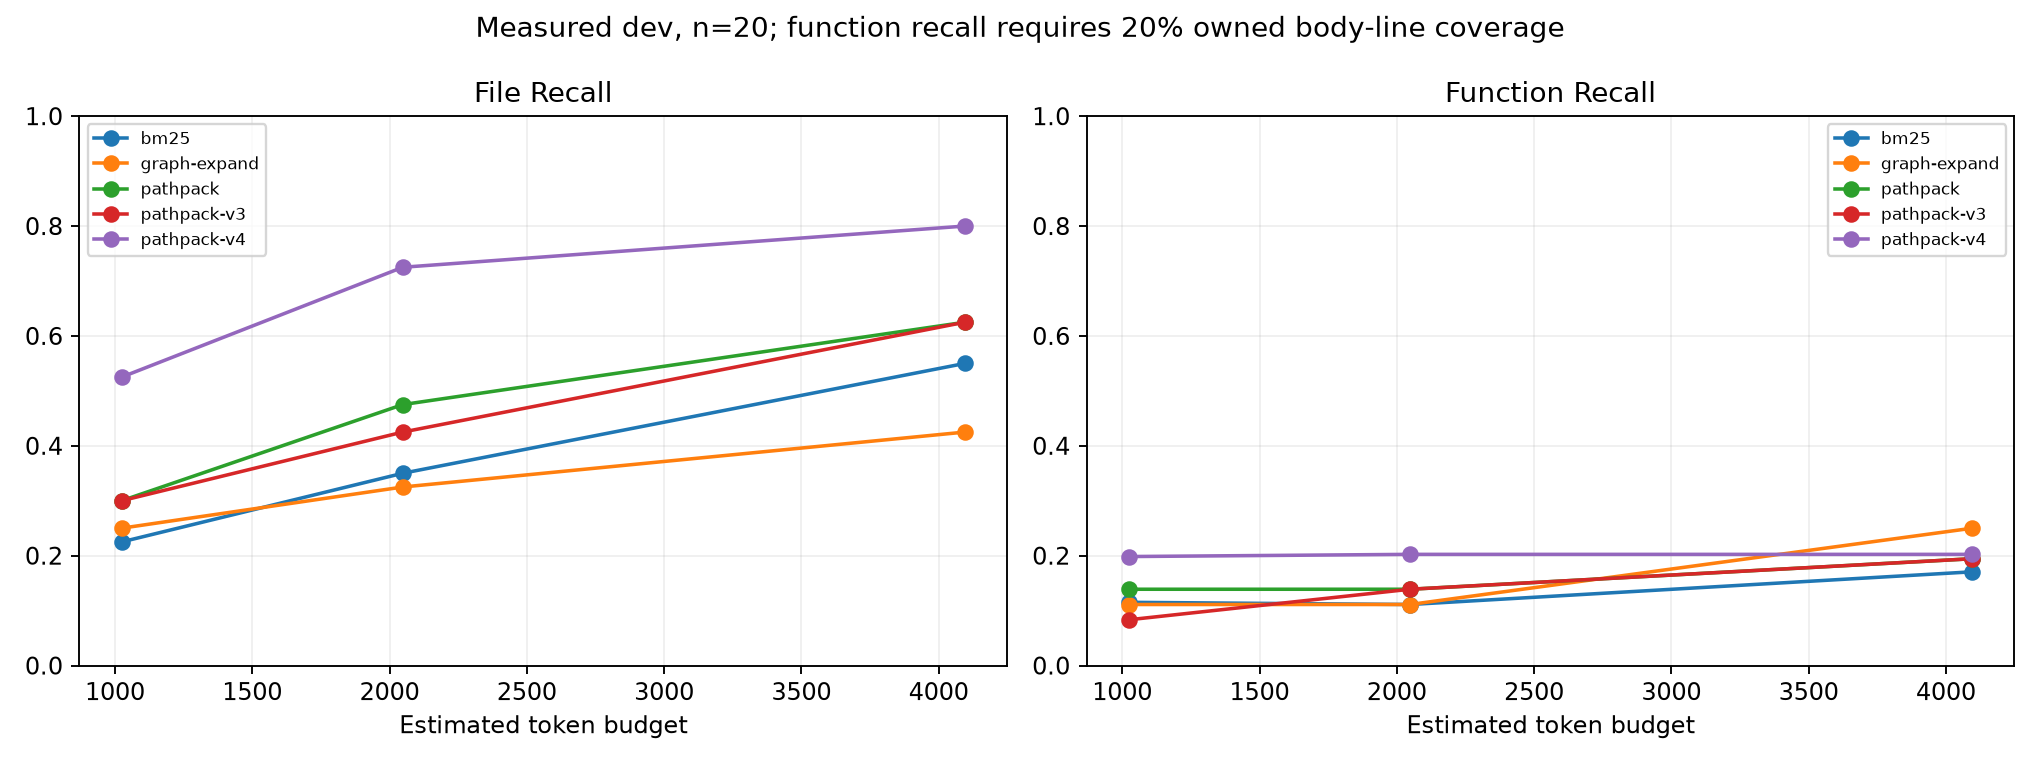

In [7]:
summary=pd.read_csv(RUN/'summary.csv')
main=summary[~summary.method.str.contains('/')]
display(main.round(4))
print('Embedding baseline:',metadata['embedding_baseline'])
display(pd.read_csv(RUN/'graph_inventory.csv')[['scan_sec','legacy_index_sec','adaptive_index_sec','chunks']].describe().round(3))
display(Image(filename=str(RUN/'figures/recall_vs_budget.png')))


## 7. Абляции и неопределённость

Full, No Graph, No Diversity, No Chunking, No Symbol Score, No Cost Adjustment отличаются только указанным компонентом. Оценка проводится на dev. Bootstrap использует одинаковые instance_id, фиксированный seed 42 и 2000 повторений; таблица содержит wins/ties/losses. Доверительные интервалы на 20 задачах описывают неопределённость, а не устанавливают научную новизну.


,method,budget,tasks,file_recall,file_recall_evaluable,function_recall,function_recall_evaluable,complete_function_recall,complete_function_recall_evaluable,changed_line_recall,changed_line_recall_evaluable,latency_sec,token_utilization,tokens_est,useful_functions_per_1k,complete_label_tasks,partial_label_tasks
13,pathpack-v4,2048,20,0.725,20,0.2024,18,0.0913,18,0.1480,14,0.5709,0.9924,2032.50,0.1640,4,16
16,pathpack-v4/no-chunking,2048,20,0.725,20,0.1944,18,0.1944,18,0.1429,14,0.6793,0.9362,1917.40,0.1207,4,16
19,pathpack-v4/no-cost,2048,20,0.625,20,0.1944,18,0.0833,18,0.1480,14,0.6209,0.9940,2035.70,0.1089,4,16
22,pathpack-v4/no-diversity,2048,20,0.425,20,0.1667,18,0.1111,18,0.1480,14,0.2458,0.9955,2038.80,0.2728,4,16
25,pathpack-v4/no-graph,2048,20,0.675,20,0.1151,18,0.0595,18,0.1718,14,0.5950,0.9944,2036.55,0.0817,4,16
28,pathpack-v4/no-symbol,2048,20,0.725,20,0.2024,18,0.0913,18,0.1480,14,0.5828,0.9926,2032.80,0.1634,4,16


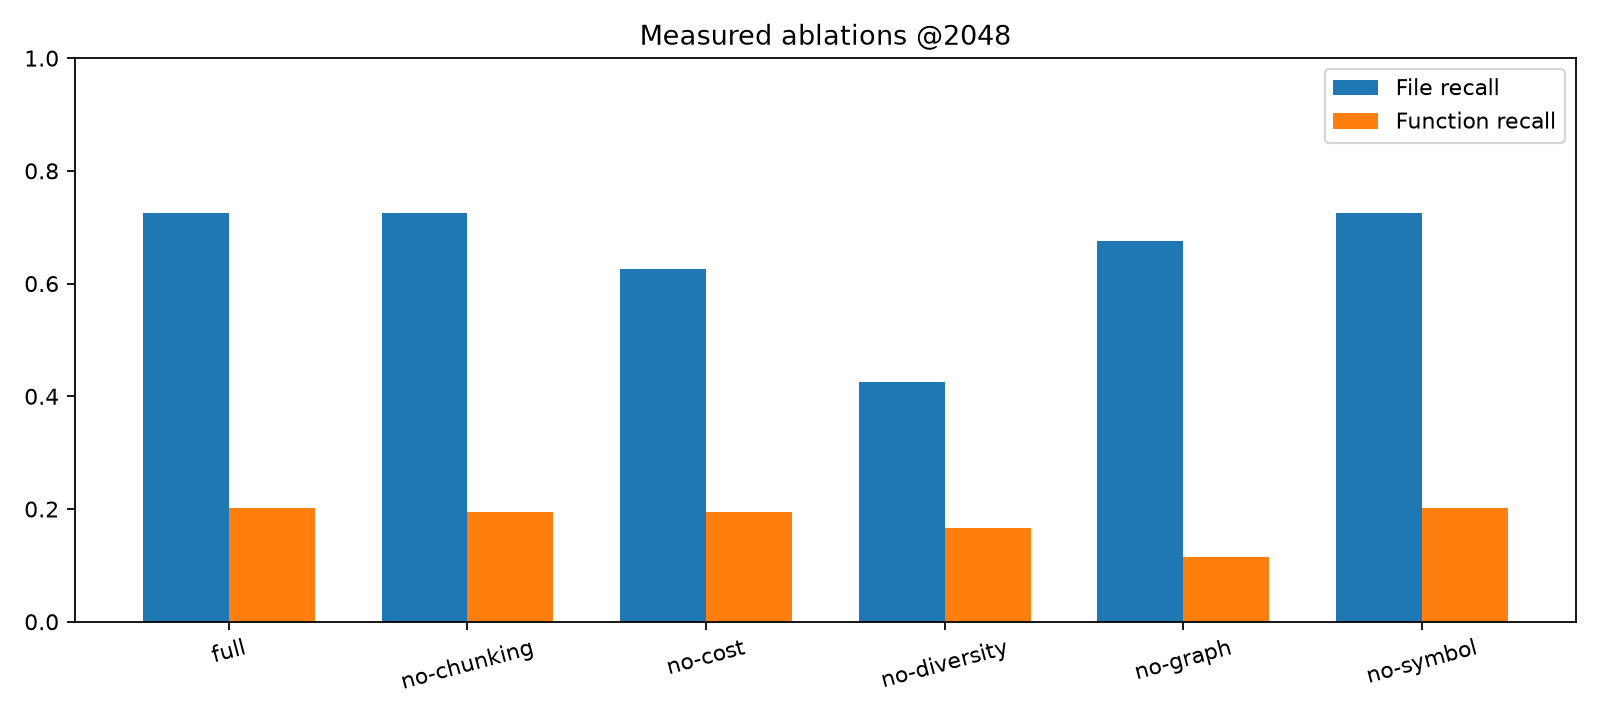

,candidate,baseline,budget,metric,n,difference,ci95,wins,ties,losses
0,pathpack-v4,bm25,2048,file_recall,20,0.375000,"[0.175, 0.6]",8,12,0
1,pathpack-v4,bm25,2048,function_recall,18,0.091270,"[0.0, 0.230159]",3,15,0
2,pathpack-v4,bm25,2048,changed_line_recall,14,0.005102,"[0.0, 0.015306]",1,13,0
3,pathpack-v4,graph-expand,2048,file_recall,20,0.400000,"[0.225, 0.6]",9,11,0
4,pathpack-v4,graph-expand,2048,function_recall,18,0.091270,"[0.0, 0.230159]",3,15,0
5,pathpack-v4,graph-expand,2048,changed_line_recall,14,0.005102,"[0.0, 0.015306]",1,13,0
6,pathpack-v4,pathpack,2048,file_recall,20,0.250000,"[0.0, 0.5]",7,11,2
7,pathpack-v4,pathpack,2048,function_recall,18,0.063492,"[0.0, 0.18254]",2,16,0
8,pathpack-v4,pathpack,2048,changed_line_recall,14,0.005102,"[0.0, 0.015306]",1,13,0
9,pathpack-v4,pathpack-v3,2048,file_recall,20,0.300000,"[0.05, 0.55]",7,12,1


In [8]:
ablations=summary[(summary.method.str.startswith('pathpack-v4'))&(summary.budget==2048)]
display(ablations.round(4))
display(Image(filename=str(RUN/'figures/ablations_2048.png')))
comparisons=json.loads((RUN/'comparisons.json').read_text())
display(pd.DataFrame([r for r in comparisons if r['budget']==2048]))


## 8. Ошибки, корректность и воспроизводимость

Gold-разметка используется только модулем scoring после завершения retrieval. Пропуски разметки новых файлов/функций, вставок и модульных изменений перечислены явно; неизвестные значения не приравниваются к нулю. File Recall усредняется по задачам с retrievable Python-файлами; Function Recall — по задачам с сопоставимыми функциями; Changed Line Recall — по задачам с точными удалёнными/заменёнными старыми строками. Useful Functions/1K — найденные по правилу покрытия gold-функции ×1000 / стоимость контекста, затем macro mean по function-evaluable задачам.

Следующий шаг исследования определяется измеренными результатами. Новый финальный holdout не запускался; прежние 60 test-задач остаются исследовательскими.


In [9]:
audit=json.loads((RUN/'audit.json').read_text())
print('Audit OK:',audit['ok'],'| predictions:',audit['predictions'],'| violations:',audit['violations'])
losing=json.loads((RUN/'losing_cases.json').read_text())
display(pd.DataFrame(losing).head(20))
labels=[json.loads(s) for s in (RUN/'scoring_labels.jsonl').read_text().splitlines()]
print('Label completeness:',pd.Series([r['label_completeness'] for r in labels]).value_counts().to_dict())
print('Frozen code source:',RUN/'code_snapshot','| config:',RUN/'run.json')
assert audit['ok']


Audit OK: True | predictions: 600 | violations: []


,instance_id,budget,baseline,metric,v4,baseline_value,diagnostics
0,django__django-14580,1024,pathpack,file_recall,0.0,1.0,[]
1,django__django-14580,1024,pathpack-v3,file_recall,0.0,1.0,[]
2,django__django-14580,2048,pathpack,file_recall,0.0,1.0,[]
3,pydata__xarray-6599,2048,pathpack,file_recall,0.0,1.0,[]
4,django__django-14580,2048,pathpack-v3,file_recall,0.0,1.0,[]
5,sphinx-doc__sphinx-7985,4096,bm25,function_recall,0.0,1.0,"[correct_file_missed_function, ranked_target_d..."
6,scikit-learn__scikit-learn-9288,4096,bm25,file_recall,0.0,1.0,[]
7,django__django-14580,4096,pathpack,file_recall,0.0,1.0,[]
8,pydata__xarray-6599,4096,pathpack,file_recall,0.0,1.0,[]
9,psf__requests-1921,4096,pathpack,function_recall,0.0,1.0,"[correct_file_missed_function, ranked_target_d..."


Label completeness: {'partial': 16, 'complete': 4}
Frozen code source: /Users/aleksandrvorobev/Downloads/CodeGraph-RAG-v0.2/output/v04_dev/code_snapshot | config: /Users/aleksandrvorobev/Downloads/CodeGraph-RAG-v0.2/output/v04_dev/run.json
